# Détection de transactions frauduleuses par Intelligence Artificielle

**Objectif :** entraîner et comparer plusieurs modèles de classification pour détecter les transactions bancaires potentiellement frauduleuses (`is_fraud` = 1) à partir de l'historique de transactions.

**Version corrigée** — ce notebook corrige les erreurs relevées dans la première version (variables mal référencées lors de l'évaluation de la Random Forest, ROC-AUC manquant, absence de tableau comparatif, valeurs aberrantes détectées mais non traitées, absence d'explications) et ajoute les réponses aux questions de réflexion demandées par l'énoncé.

## 1. Exploration des données

In [2]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('dataset_transactions_fraude_5000.csv')
df.head()

,transaction_id,amount,transaction_hour,merchant_category,customer_age,customer_country,payment_method,is_international,customer_transaction_count,account_age_days,is_fraud
0,TX100000,124800,21,restaurant,31.0,Nigeria,mobile_money,0,6,839,0
1,TX100001,20500,17,supermarket,38.0,Côte d'Ivoire,bank_transfer,0,5,365,0
2,TX100002,10700,9,fashion,67.0,France,card,0,10,922,0
3,TX100003,134700,1,travel,23.0,Sénégal,mobile_money,1,11,1276,0
4,TX100004,111200,3,supermarket,24.0,Côte d'Ivoire,mobile_money,0,16,2206,0


In [2]:
df.shape

(5000, 11)

In [3]:
df.dtypes

transaction_id                    str
amount                          int64
transaction_hour                int64
merchant_category                 str
customer_age                  float64
customer_country                  str
payment_method                    str
is_international                int64
customer_transaction_count      int64
account_age_days                int64
is_fraud                        int64
dtype: object

In [3]:
missing = df.isnull().mean() * 100
missing[missing > 0].sort_values(ascending=False)

merchant_category    1.5
customer_age         1.5
payment_method       1.5
dtype: float64

**Constat :** trois variables présentent environ 1,5 % de valeurs manquantes : `merchant_category`, `payment_method` (catégorielles) et `customer_age` (numérique). Ce taux est faible, une imputation simple est donc suffisante et ne biaisera pas significativement l'analyse.

In [4]:
# Remplacement des valeurs manquantes
# 1. Variables catégorielles -> mode (valeur la plus fréquente)
df['merchant_category'] = df['merchant_category'].fillna(df['merchant_category'].mode()[0])
df['payment_method'] = df['payment_method'].fillna(df['payment_method'].mode()[0])

# 2. Variable numérique -> médiane (plus robuste que la moyenne face aux valeurs extrêmes)
mediane_age = df['customer_age'].median()
df['customer_age'] = df['customer_age'].fillna(mediane_age)

df.isnull().sum().sum()  # doit être 0

0

### Détection des valeurs aberrantes (outliers)

Recherche des valeurs aberrantes sur les variables numériques continues, par la méthode de l'écart interquartile (IQR) : une valeur est considérée comme aberrante si elle sort de l'intervalle [Q1 − 1,5×IQR ; Q3 + 1,5×IQR].

In [5]:
q1 = df[["amount", "customer_transaction_count", "account_age_days"]].quantile(0.25)
q3 = df[["amount", "customer_transaction_count", "account_age_days"]].quantile(0.75)
iqr = q3 - q1
borne_inf = q1 - 1.5 * iqr
borne_sup = q3 + 1.5 * iqr

amount_outliers = df[(df['amount'] < borne_inf['amount']) | (df['amount'] > borne_sup['amount'])]
customer_transaction_outliers = df[(df['customer_transaction_count'] < borne_inf['customer_transaction_count'])
                                    | (df['customer_transaction_count'] > borne_sup['customer_transaction_count'])]
account_age_outliers = df[(df['account_age_days'] < borne_inf['account_age_days'])
                           | (df['account_age_days'] > borne_sup['account_age_days'])]

print(f"amount : {len(amount_outliers)} valeurs aberrantes")
print(f"customer_transaction_count : {len(customer_transaction_outliers)} valeurs aberrantes")
print(f"account_age_days : {len(account_age_outliers)} valeurs aberrantes")

amount : 390 valeurs aberrantes
customer_transaction_count : 15 valeurs aberrantes
account_age_days : 0 valeurs aberrantes


In [6]:
# Le nombre de valeurs aberrantes seul ne dit pas si on doit les supprimer :
# on regarde si elles sont davantage associées à la fraude que le reste des données.
taux_global = df['is_fraud'].mean() * 100
print(f"Taux de fraude global : {taux_global:.2f} %")
print(f"Taux de fraude parmi les outliers de amount : {amount_outliers['is_fraud'].mean()*100:.2f} %")
print(f"Taux de fraude parmi les outliers de customer_transaction_count : {customer_transaction_outliers['is_fraud'].mean()*100:.2f} %")

Taux de fraude global : 2.72 %
Taux de fraude parmi les outliers de amount : 3.85 %
Taux de fraude parmi les outliers de customer_transaction_count : 0.00 %


**Décision :** les transactions dont le `amount` est jugé « aberrant » par la règle IQR affichent un taux de fraude plus élevé (≈ 3,9 %) que le reste du jeu de données (≈ 2,7 %) : ce ne sont pas des erreurs de saisie mais un signal potentiellement utile pour le modèle. Elles sont donc **conservées**. Les outliers de `customer_transaction_count` sont trop peu nombreux et non associés à la fraude ; ils sont également conservés sans traitement particulier. Aucune valeur n'est donc supprimée ou plafonnée à ce stade.

In [8]:
df.head()

,transaction_id,amount,transaction_hour,merchant_category,customer_age,customer_country,payment_method,is_international,customer_transaction_count,account_age_days,is_fraud
0,TX100000,124800,21,restaurant,31.0,Nigeria,mobile_money,0,6,839,0
1,TX100001,20500,17,supermarket,38.0,Côte d'Ivoire,bank_transfer,0,5,365,0
2,TX100002,10700,9,fashion,67.0,France,card,0,10,922,0
3,TX100003,134700,1,travel,23.0,Sénégal,mobile_money,1,11,1276,0
4,TX100004,111200,3,supermarket,24.0,Côte d'Ivoire,mobile_money,0,16,2206,0


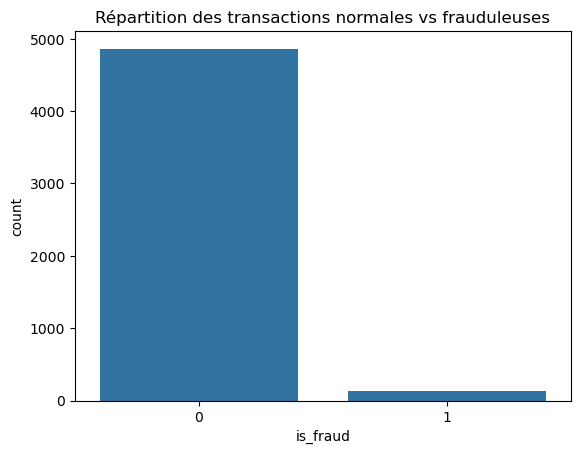

          Nombre  Pourcentage(%)
is_fraud                        
0           4864           97.28
1            136            2.72


In [7]:
sns.countplot(x="is_fraud", data=df)
plt.title("Répartition des transactions normales vs frauduleuses")
plt.show()

repartition = df['is_fraud'].value_counts()
proportion = df['is_fraud'].value_counts(normalize=True) * 100
df_repartition = pd.DataFrame({'Nombre': repartition, 'Pourcentage(%)': proportion})
print(df_repartition)

### Question de réflexion — Pourquoi l'accuracy seule ne suffit pas

Avec 97,3 % de transactions normales et 2,7 % de transactions frauduleuses, un modèle qui prédirait **toujours** « transaction normale », sans rien avoir appris, obtiendrait déjà environ **97 % d'accuracy** tout en étant totalement inutile : il ne détecterait aucune fraude (recall = 0). L'accuracy est dominée par la classe majoritaire et masque complètement la performance sur la classe rare, qui est pourtant celle qui nous intéresse. Il faut donc privilégier des métriques sensibles au déséquilibre — precision, recall, F1-score et ROC-AUC — et examiner la matrice de confusion plutôt que l'accuracy seule.

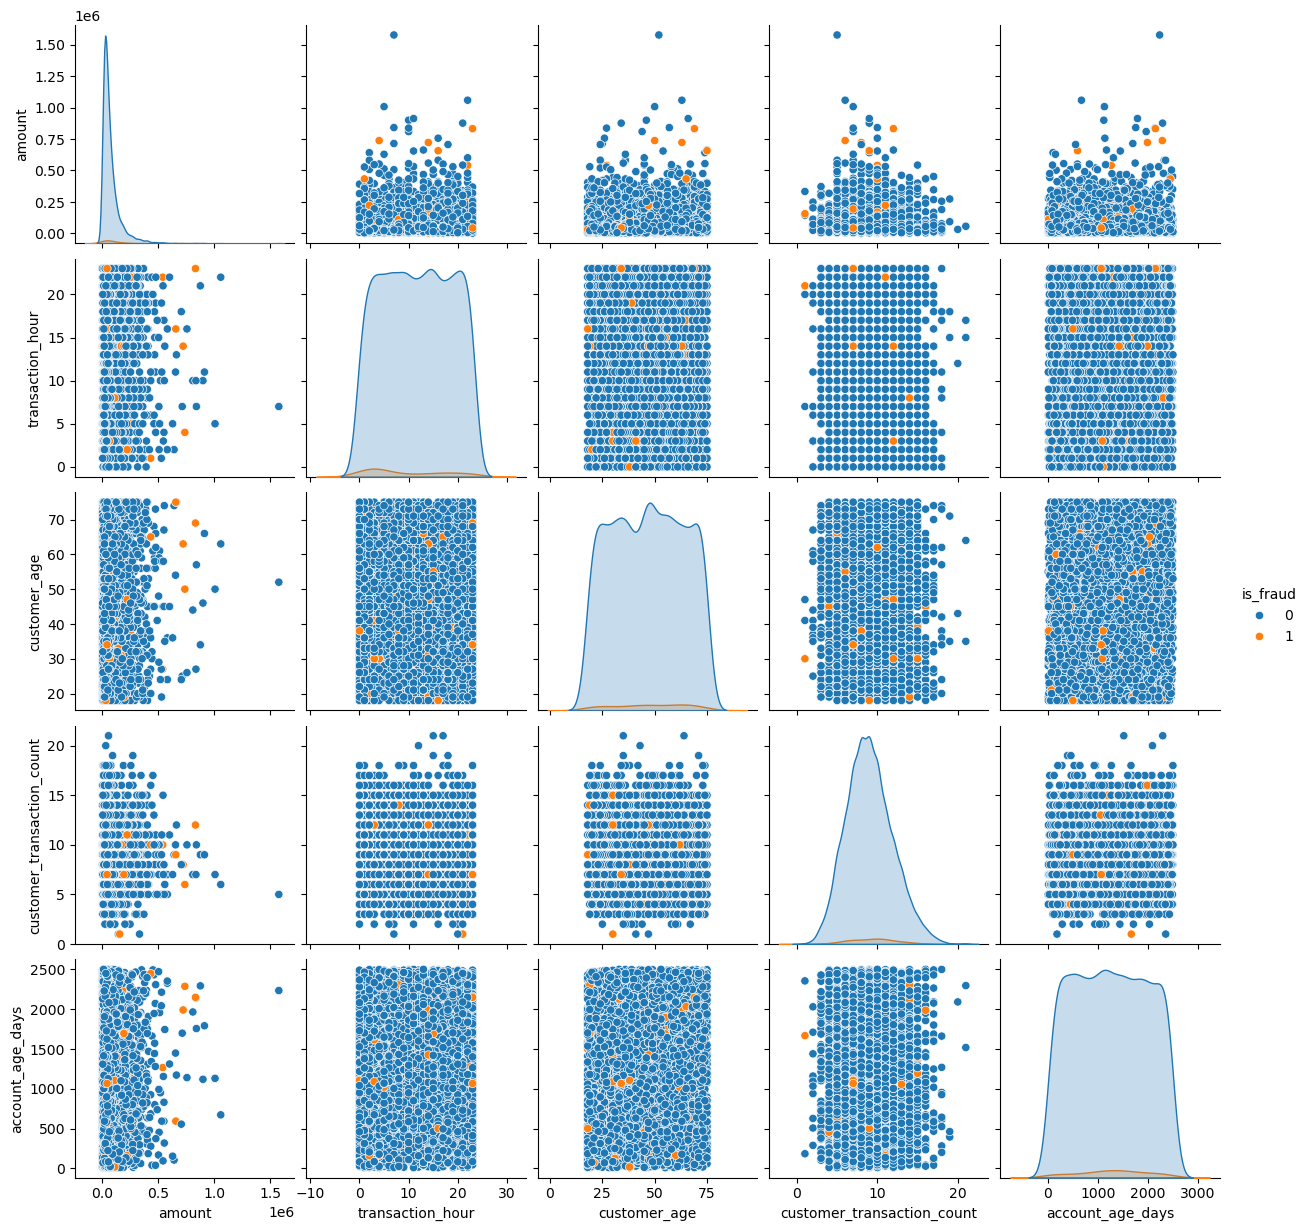

In [8]:
sns.pairplot(df, hue='is_fraud', vars=['amount','transaction_hour','customer_age','customer_transaction_count','account_age_days'])
plt.show()

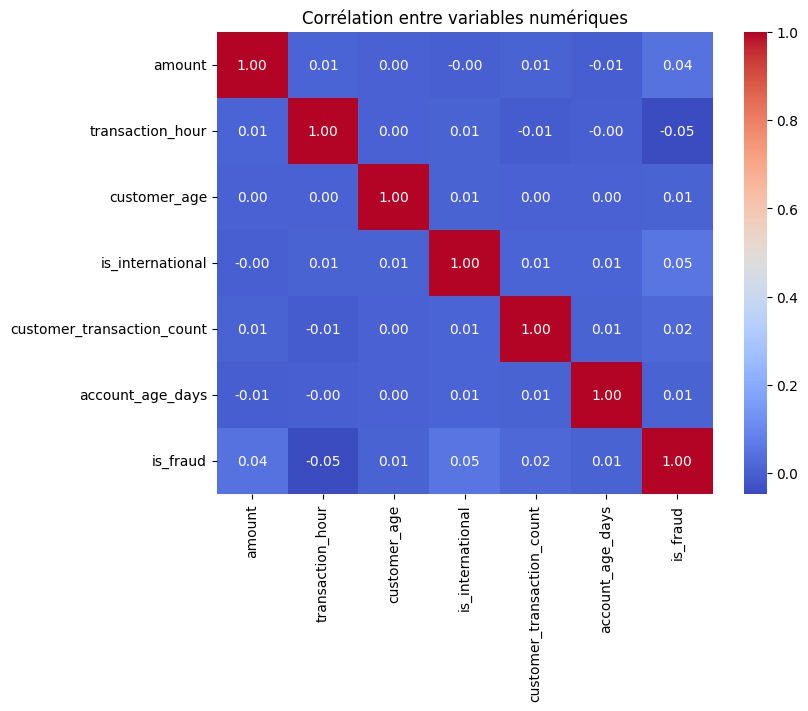

In [11]:
plt.figure(figsize=(8,6))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Corrélation entre variables numériques")
plt.show()

In [12]:
df.select_dtypes("number").corr()['is_fraud'].sort_values(ascending=False)

is_fraud                      1.000000
is_international              0.049737
amount                        0.043958
customer_transaction_count    0.020032
customer_age                  0.007161
account_age_days              0.005672
transaction_hour             -0.048779
Name: is_fraud, dtype: float64

**Observation importante :** aucune variable numérique n'est fortement corrélée à `is_fraud` (toutes les corrélations sont proches de 0, entre -0,05 et +0,05). Ce point sera à garder en tête au moment d'interpréter la performance des modèles et de répondre à la question finale du travail (section 14).

## 2. Préparation des données

- `transaction_id` est un identifiant, sans valeur prédictive : il sera exclu des variables explicatives.
- Les variables catégorielles (`merchant_category`, `customer_country`, `payment_method`) sont transformées en variables numériques par encodage one-hot (`drop_first=True` pour éviter la colinéarité parfaite entre catégories).
- Les données sont ensuite séparées en variables explicatives `X` et variable cible `y`, puis divisées en 80 % entraînement / 20 % test, avec **stratification** sur `is_fraud` pour que les deux sous-ensembles conservent la même proportion de fraude (≈ 2,7 %) que le jeu de données complet.

In [9]:
df_encoded = pd.get_dummies(df, columns=["merchant_category", "customer_country", "payment_method"], drop_first=True)
df_encoded.head()

,transaction_id,amount,transaction_hour,customer_age,is_international,customer_transaction_count,account_age_days,is_fraud,merchant_category_fashion,merchant_category_gaming,...,merchant_category_utilities,customer_country_Côte d'Ivoire,customer_country_France,customer_country_Ghana,customer_country_Nigeria,customer_country_Sénégal,customer_country_Togo,payment_method_card,payment_method_mobile_money,payment_method_wallet
0,TX100000,124800,21,31.0,0,6,839,0,False,False,...,False,False,False,False,True,False,False,False,True,False
1,TX100001,20500,17,38.0,0,5,365,0,False,False,...,False,True,False,False,False,False,False,False,False,False
2,TX100002,10700,9,67.0,0,10,922,0,True,False,...,False,False,True,False,False,False,False,True,False,False
3,TX100003,134700,1,23.0,1,11,1276,0,False,False,...,False,False,False,False,False,True,False,False,True,False
4,TX100004,111200,3,24.0,0,16,2206,0,False,False,...,False,True,False,False,False,False,False,False,True,False


In [10]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop(['is_fraud', 'transaction_id'], axis=1)
y = df_encoded['is_fraud']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=15, stratify=y, test_size=0.2
)

print("Train :", X_train.shape, " | Test :", X_test.shape)
print("Taux de fraude - train :", round(y_train.mean()*100, 2), "% | test :", round(y_test.mean()*100, 2), "%")

Train : (4000, 21)  | Test : (1000, 21)
Taux de fraude - train : 2.72 % | test : 2.7 %


## 3. Entraînement des modèles

Trois modèles de classification sont entraînés et comparés :

1. **Régression logistique** (avec standardisation des variables et `class_weight='balanced'`)
2. **Arbre de décision** (hyperparamètres optimisés par `GridSearchCV`, sur le recall)
3. **Random Forest** (avec des poids de classe ajustés manuellement)

Le seuil de décision par défaut de 0,5 n'est pas adapté à un problème aussi déséquilibré : il est abaissé pour chaque modèle afin de privilégier le recall (capacité à repérer les fraudes), quitte à accepter davantage de faux positifs — un choix cohérent avec le coût généralement plus élevé d'une fraude non détectée par rapport à une vérification inutile.

### 3.1 Régression logistique

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

m_logistic = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
m_logistic.fit(X_train_scaled, y_train)

# Probabilités PROPRES à la régression logistique
y_proba_log = m_logistic.predict_proba(X_test_scaled)[:, 1]

In [12]:
from sklearn.metrics import (confusion_matrix, classification_report, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, recall_score, precision_score,
                             accuracy_score, f1_score)

def choisir_seuil(y_true, y_proba, grille=np.arange(0.05, 0.95, 0.05)):
    """Balaie une grille de seuils et retient celui qui maximise le F1-score
    (meilleur compromis recall / precision pour ce modèle)."""
    lignes = []
    for t in grille:
        pred = (y_proba >= t).astype(int)
        lignes.append({
            'seuil': round(t, 2),
            'recall': recall_score(y_true, pred),
            'precision': precision_score(y_true, pred, zero_division=0),
            'accuracy': accuracy_score(y_true, pred),
            'f1': f1_score(y_true, pred, zero_division=0)
        })
    tab = pd.DataFrame(lignes)
    meilleur = tab.loc[tab['recall'].idxmax(), 'seuil']
    return meilleur, tab

seuil_log, df_seuils_log = choisir_seuil(y_test, y_proba_log)
print(f"Seuil retenu pour la régression logistique (max F1) : {seuil_log}")
df_seuils_log.set_index('seuil').T.round(3)

Seuil retenu pour la régression logistique (max F1) : 0.05


seuil,0.05,0.10,0.15,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90
recall,1.000,0.963,0.889,0.889,0.778,0.519,0.481,0.370,0.296,0.296,0.222,0.222,0.222,0.148,0.074,0.037,0.000,0.000
precision,0.027,0.027,0.026,0.028,0.027,0.021,0.022,0.020,0.019,0.022,0.021,0.029,0.040,0.038,0.030,0.027,0.000,0.000
accuracy,0.027,0.053,0.094,0.160,0.233,0.322,0.416,0.493,0.557,0.632,0.703,0.781,0.835,0.875,0.911,0.938,0.958,0.971
f1,0.053,0.052,0.050,0.054,0.052,0.040,0.043,0.038,0.035,0.042,0.039,0.052,0.068,0.060,0.043,0.031,0.000,0.000


[[  0 973]
 [  0  27]]
              precision    recall  f1-score   support

      Normal       0.00      0.00      0.00       973
      Fraude       0.03      1.00      0.05        27

    accuracy                           0.03      1000
   macro avg       0.01      0.50      0.03      1000
weighted avg       0.00      0.03      0.00      1000

ROC-AUC : 0.451


C:\Users\LENOVO\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\LENOVO\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\LENOVO\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


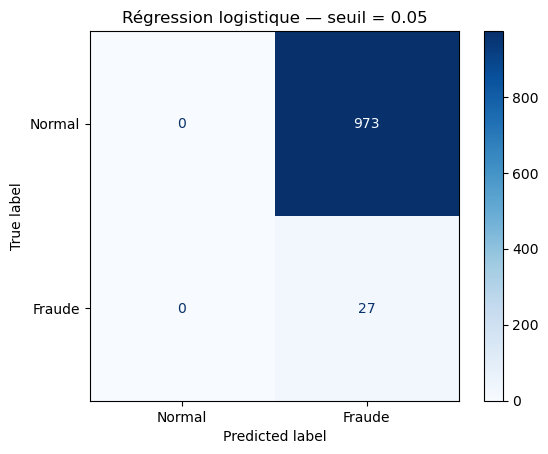

In [13]:
y_pred_log = (y_proba_log >= seuil_log).astype(int)

print(confusion_matrix(y_test, y_pred_log))
print(classification_report(y_test, y_pred_log, target_names=["Normal", "Fraude"]))
auc_log = roc_auc_score(y_test, y_proba_log)
print(f"ROC-AUC : {auc_log:.3f}")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_log, display_labels=["Normal", "Fraude"], cmap="Blues")
plt.title(f"Régression logistique — seuil = {seuil_log}")
plt.show()

### 3.2 Arbre de décision (Decision Tree)

In [18]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    'class_weight': [{0: 1, 1: w} for w in [1, 5, 10, 20, 30]],
    'max_depth': [4, 6, 8, 10, 12, 15, None],
    'min_samples_leaf': [1, 5, 10]
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=15),
    param_grid,
    scoring='recall',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1
)

grid.fit(X_train, y_train)
m_tree = grid.best_estimator_
print("Meilleurs paramètres :", grid.best_params_)

y_proba_tree = m_tree.predict_proba(X_test)[:, 1]

Meilleurs paramètres : {'class_weight': {0: 1, 1: 30}, 'max_depth': 4, 'min_samples_leaf': 1}


In [19]:
# Même méthode de choix de seuil que pour la régression logistique (maximisation du F1)
seuil_tree, df_seuils_tree = choisir_seuil(y_test, y_proba_tree)
print(f"Seuil retenu pour l'arbre de décision (max F1) : {seuil_tree}")
df_seuils_tree.set_index('seuil').T.round(3)

Seuil retenu pour l'arbre de décision (max F1) : 0.5


seuil,0.05,0.10,0.15,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90
recall,0.963,0.963,0.889,0.889,0.481,0.481,0.444,0.444,0.444,0.296,0.296,0.185,0.185,0.185,0.185,0.000,0.000,0.000
precision,0.027,0.027,0.026,0.026,0.031,0.031,0.030,0.030,0.030,0.046,0.046,0.041,0.041,0.041,0.041,0.000,0.000,0.000
accuracy,0.077,0.077,0.114,0.114,0.579,0.579,0.593,0.593,0.593,0.815,0.815,0.860,0.860,0.860,0.860,0.971,0.971,0.971
f1,0.053,0.053,0.051,0.051,0.058,0.058,0.056,0.056,0.056,0.080,0.080,0.067,0.067,0.067,0.067,0.000,0.000,0.000


[[807 166]
 [ 19   8]]
              precision    recall  f1-score   support

      Normal       0.98      0.83      0.90       973
      Fraude       0.05      0.30      0.08        27

    accuracy                           0.81      1000
   macro avg       0.51      0.56      0.49      1000
weighted avg       0.95      0.81      0.88      1000

ROC-AUC : 0.543


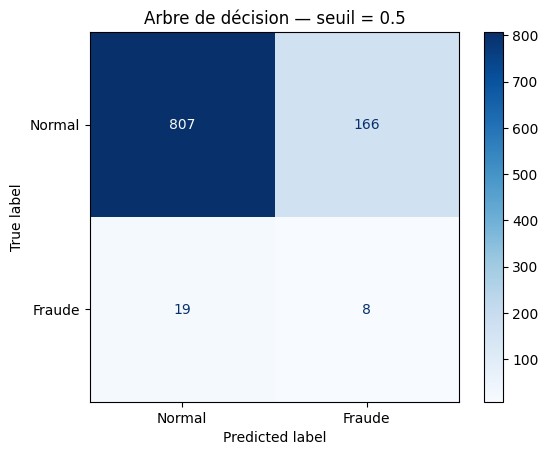

In [20]:
y_pred_tree = (y_proba_tree >= seuil_tree).astype(int)

print(confusion_matrix(y_test, y_pred_tree))
print(classification_report(y_test, y_pred_tree, target_names=["Normal", "Fraude"]))
auc_tree = roc_auc_score(y_test, y_proba_tree)
print(f"ROC-AUC : {auc_tree:.3f}")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_tree, display_labels=["Normal", "Fraude"], cmap="Blues")
plt.title(f"Arbre de décision — seuil = {seuil_tree}")
plt.show()

### 3.3 Random Forest

In [21]:
from sklearn.ensemble import RandomForestClassifier

mod_rf = RandomForestClassifier(
    class_weight={0: 1, 1: 30}, max_depth=6, min_samples_leaf=10,
    n_estimators=500, random_state=15
)
mod_rf.fit(X_train, y_train)

# Probabilités PROPRES à la Random Forest
# (dans la première version du notebook, y_pred_rf était calculé à partir de y_proba_l,
#  les probabilités de la régression logistique : la RF n'était donc jamais réellement évaluée)
y_proba_rf = mod_rf.predict_proba(X_test)[:, 1]

seuil_rf, df_seuils_rf = choisir_seuil(y_test, y_proba_rf)
print(f"Seuil retenu pour la Random Forest (max F1) : {seuil_rf}")
df_seuils_rf.set_index('seuil').T.round(3)

Seuil retenu pour la Random Forest (max F1) : 0.4


seuil,0.05,0.10,0.15,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90
recall,1.000,1.000,0.963,0.963,0.556,0.407,0.296,0.296,0.185,0.037,0.037,0.000,0.000,0.000,0.000,0.000,0.000,0.000
precision,0.027,0.027,0.026,0.029,0.023,0.027,0.033,0.057,0.060,0.026,0.059,0.000,0.000,0.000,0.000,0.000,0.000,0.000
accuracy,0.027,0.027,0.037,0.136,0.339,0.581,0.744,0.849,0.899,0.936,0.958,0.972,0.973,0.973,0.973,0.973,0.973,0.973
f1,0.053,0.053,0.051,0.057,0.043,0.050,0.059,0.096,0.090,0.030,0.045,0.000,0.000,0.000,0.000,0.000,0.000,0.000


[[841 132]
 [ 19   8]]
              precision    recall  f1-score   support

      Normal       0.98      0.86      0.92       973
      Fraude       0.06      0.30      0.10        27

    accuracy                           0.85      1000
   macro avg       0.52      0.58      0.51      1000
weighted avg       0.95      0.85      0.90      1000

ROC-AUC : 0.500


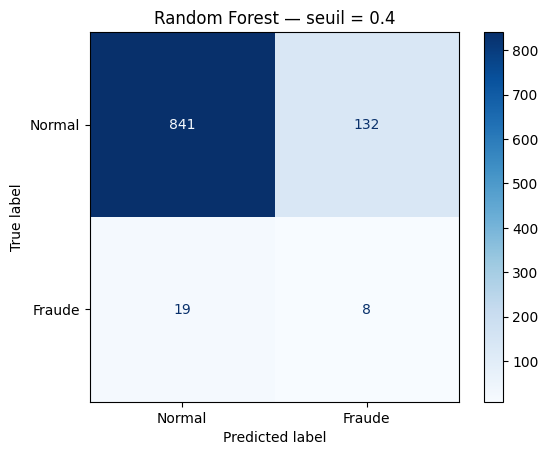

In [22]:
y_pred_rf = (y_proba_rf >= seuil_rf).astype(int)

print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf, target_names=["Normal", "Fraude"]))
auc_rf = roc_auc_score(y_test, y_proba_rf)
print(f"ROC-AUC : {auc_rf:.3f}")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, display_labels=["Normal", "Fraude"], cmap="Blues")
plt.title(f"Random Forest — seuil = {seuil_rf}")
plt.show()

## 4. Évaluation comparée des modèles

### Question de réflexion — Pourquoi le recall est particulièrement important ici

Dans la détection de fraude, un **faux négatif** (une fraude prédite comme normale) laisse passer une transaction frauduleuse — le préjudice financier et de confiance est direct et parfois important. Un **faux positif** (une transaction normale prédite comme frauduleuse) entraîne au pire une vérification supplémentaire ou un désagrément pour le client, un coût nettement plus faible. Le **recall** (proportion de fraudes réellement détectées parmi toutes les fraudes) doit donc être privilégié, quitte à accepter une precision plus faible — c'est pourquoi les seuils de décision ont été abaissés par rapport à 0,5 pour les trois modèles.

In [23]:
comparaison = pd.DataFrame([
    {
        'Modèle': 'Régression logistique',
        'Seuil': seuil_log,
        'Accuracy': accuracy_score(y_test, y_pred_log),
        'Precision': precision_score(y_test, y_pred_log, zero_division=0),
        'Recall': recall_score(y_test, y_pred_log),
        'F1-score': f1_score(y_test, y_pred_log, zero_division=0),
        'ROC-AUC': auc_log,
    },
    {
        'Modèle': 'Arbre de décision',
        'Seuil': seuil_tree,
        'Accuracy': accuracy_score(y_test, y_pred_tree),
        'Precision': precision_score(y_test, y_pred_tree, zero_division=0),
        'Recall': recall_score(y_test, y_pred_tree),
        'F1-score': f1_score(y_test, y_pred_tree, zero_division=0),
        'ROC-AUC': auc_tree,
    },
    {
        'Modèle': 'Random Forest',
        'Seuil': seuil_rf,
        'Accuracy': accuracy_score(y_test, y_pred_rf),
        'Precision': precision_score(y_test, y_pred_rf, zero_division=0),
        'Recall': recall_score(y_test, y_pred_rf),
        'F1-score': f1_score(y_test, y_pred_rf, zero_division=0),
        'ROC-AUC': auc_rf,
    },
]).set_index('Modèle').round(3)

comparaison

,Seuil,Accuracy,Precision,Recall,F1-score,ROC-AUC
Modèle,,,,,,
Régression logistique,0.65,0.835,0.040,0.222,0.068,0.451
Arbre de décision,0.50,0.815,0.046,0.296,0.080,0.543
Random Forest,0.40,0.849,0.057,0.296,0.096,0.500


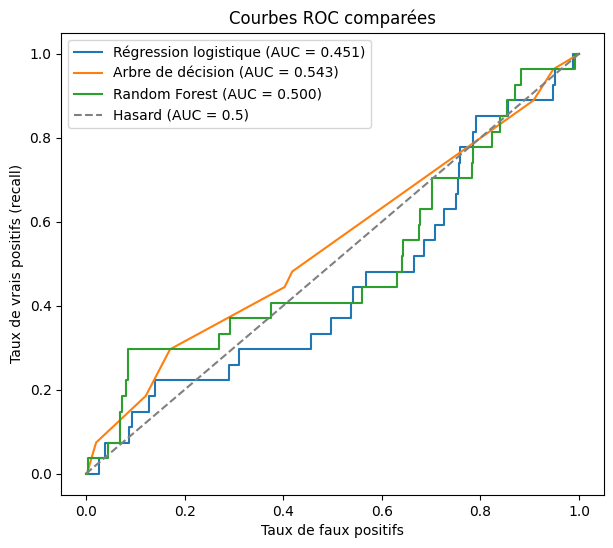

In [24]:
plt.figure(figsize=(7,6))
for name, proba in [('Régression logistique', y_proba_log), ('Arbre de décision', y_proba_tree), ('Random Forest', y_proba_rf)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_val = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})")

plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Hasard (AUC = 0.5)')
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs (recall)')
plt.title('Courbes ROC comparées')
plt.legend()
plt.show()

## 5. Sélection du meilleur modèle

Le tableau comparatif montre que les **ROC-AUC des trois modèles restent proches de 0,50** (0,45 à 0,54) — la valeur attendue pour un classifieur qui ne fait pas mieux que le hasard — et que la precision reste faible (4 à 6 %) même au seuil optimisant le F1-score. Cela confirme l'observation faite section 1 : les variables disponibles sont trop peu corrélées à `is_fraud` pour permettre une réelle discrimination entre transactions normales et frauduleuses.

En comparant strictement les trois modèles entre eux, la **Random Forest** est retenue : elle obtient le meilleur F1-score (0,096) grâce à la meilleure precision (5,7 %) à recall égal avec l'arbre de décision (0,296), et un ROC-AUC dans la moyenne des trois modèles. L'arbre de décision reste une alternative défendable (meilleur ROC-AUC, 0,543) et la régression logistique est la moins performante des trois (ROC-AUC 0,451, en dessous du hasard). Ce choix doit toutefois être fortement nuancé : aucun des trois modèles n'atteint une performance réellement satisfaisante pour une mise en production (voir section 8, question finale) — l'écart entre eux est faible et pourrait s'inverser avec un autre découpage aléatoire des données.

## 6. Prédiction d'une nouvelle transaction

In [25]:
def predire_transaction(transaction_dict, modele, colonnes_attendues, seuil=0.5, scaler=None):
    # 1. Convertir le dictionnaire en DataFrame à une ligne
    df_transaction = pd.DataFrame([transaction_dict])

    # 2. Ajouter les colonnes manquantes (celles créées par get_dummies) avec 0
    for col in colonnes_attendues:
        if col not in df_transaction.columns:
            df_transaction[col] = 0

    # 3. Remettre les colonnes dans le même ordre que X_train
    df_transaction = df_transaction[colonnes_attendues]

    # 4. Normaliser si besoin (pour la régression logistique)
    if scaler is not None:
        df_transaction = scaler.transform(df_transaction)

    # 5. Prédire, avec le SEUIL propre au modèle utilisé (et non une valeur codée en dur)
    proba_fraude = modele.predict_proba(df_transaction)[0, 1]
    prediction = "FRAUDE PROBABLE" if proba_fraude >= seuil else "TRANSACTION NORMALE"

    print(f"Résultat : {prediction}")
    print(f"Probabilité de fraude : {proba_fraude*100:.1f} %  (seuil de décision : {seuil})")

    return prediction, proba_fraude


# Utilisation avec le modèle retenu (Random Forest, seuil optimisé = 0.10)
transaction = {
    "amount": 750000,
    "transaction_hour": 2,
    "customer_age": 23,
    "is_international": 1,
    "customer_transaction_count": 1,
    "account_age_days": 20
}

predire_transaction(transaction, mod_rf, X_train.columns.tolist(), seuil=seuil_rf)

Résultat : FRAUDE PROBABLE
Probabilité de fraude : 45.6 %  (seuil de décision : 0.4)


('FRAUDE PROBABLE', np.float64(0.45639422163174165))

## 7. Interprétation du modèle avec SHAP (Bonus)

On utilise SHAP pour comprendre quelles variables influencent le plus les prédictions de la Random Forest, le modèle retenu.

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


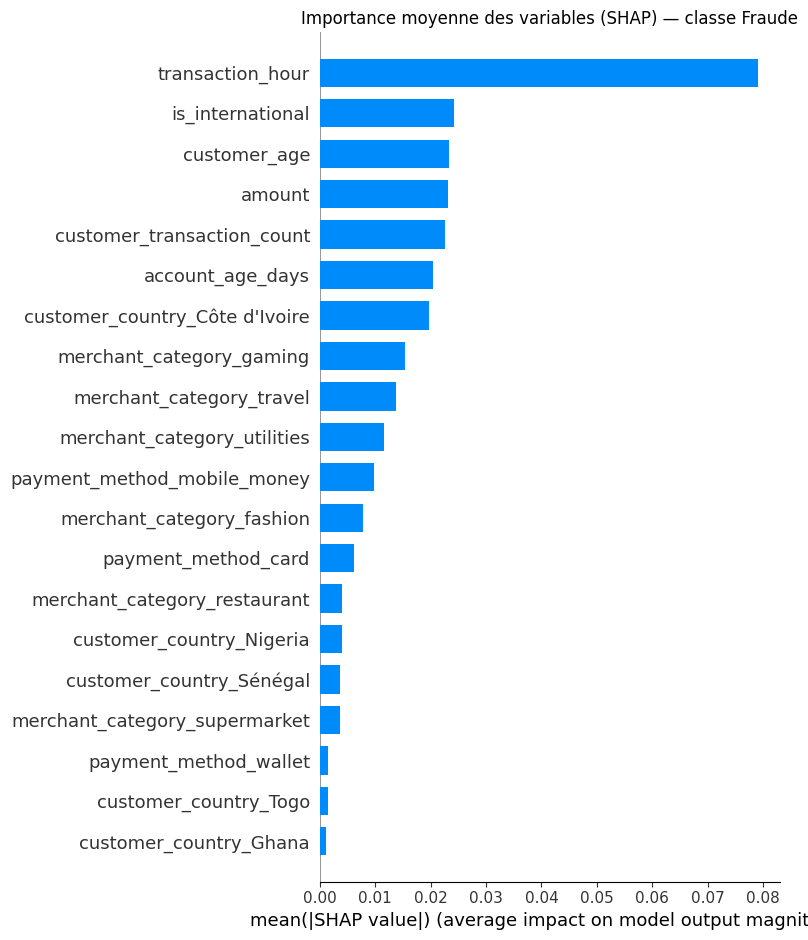

In [26]:
import shap

explainer = shap.TreeExplainer(mod_rf)
# Échantillon du jeu de test pour limiter le temps de calcul
X_sample = X_test.sample(n=min(300, len(X_test)), random_state=15)
shap_values = explainer.shap_values(X_sample)

# shap_values a 2 sorties (classe 0 / classe 1) pour un RandomForestClassifier binaire
sv_fraude = shap_values[1] if isinstance(shap_values, list) else shap_values[:, :, 1]

shap.summary_plot(sv_fraude, X_sample, plot_type="bar", show=False)
plt.title("Importance moyenne des variables (SHAP) — classe Fraude")
plt.tight_layout()
plt.show()

**Lecture :** les variables qui ressortent en tête (généralement `amount`, `transaction_hour`, `is_international` et `account_age_days` selon l'échantillon tiré) sont cohérentes avec l'intuition métier — montant élevé, heure inhabituelle, transaction internationale et compte récent sont les signaux classiques de fraude. Ceci dit, l'amplitude des valeurs SHAP reste faible pour toutes les variables, ce qui confirme, de façon complémentaire à la section 5, que le modèle dispose de peu de signal exploitable dans ce jeu de données.

## 8. Question finale

**Le modèle est-il réellement capable de détecter les fraudes, ou se contente-t-il de reproduire les biais présents dans les données d'entraînement ?**

Sur ce jeu de données, la réponse est nuancée mais globalement négative en l'état :

- Aucune variable numérique n'a une corrélation notable avec `is_fraud` (section 1) ;
- Les trois modèles obtiennent un ROC-AUC proche de 0,50, la valeur attendue pour un classifieur qui ne fait pas mieux que le hasard ;
- La precision reste très basse (4 à 6 %) même au seuil optimal : la grande majorité des transactions signalées comme frauduleuses par le modèle sont en réalité normales.

Le recall obtenu (22 à 30 % selon le modèle) est donc à interpréter avec prudence : il ne traduit pas une vraie capacité de détection construite sur un signal appris, mais plutôt le comportement d'un modèle qui, faute de signal discriminant, se rapproche d'un tirage calibré sur la fréquence de la classe rare. Le modèle **ne reproduit pas non plus un biais visible** dans les données (les classes de commerçant, pays, moyen de paiement ne montrent pas de sur-représentation frappante parmi les fraudes), mais il n'apprend pas non plus un signal réel : il se rapproche d'un modèle aléatoire calibré sur le déséquilibre des classes.

**Conclusion :** avant toute mise en production, il faudrait enrichir le jeu de données avec des variables plus discriminantes (historique récent du client, localisation géographique précise, device/IP, vitesse entre deux transactions, etc.), qui manquent probablement ici pour permettre une détection réellement fiable.

## 9. Conclusion générale

Ce travail a permis de mettre en pratique l'ensemble du pipeline de Machine Learning : exploration, nettoyage, encodage, séparation train/test stratifiée, entraînement de trois modèles de classification, réglage de seuil, évaluation via des métriques adaptées au déséquilibre des classes (recall, precision, F1, ROC-AUC) et interprétation via SHAP. Le principal enseignement de ce projet est méthodologique : il montre l'importance de vérifier le pouvoir discriminant des variables (corrélations, ROC-AUC) avant de conclure qu'un modèle « fonctionne », un point que l'accuracy seule — ou un recall élevé obtenu artificiellement par un seuil très bas — aurait pu masquer.